In [1]:
import pandas as pd
import re
import string
import matplotlib.pyplot as plt

Φόρτωση Δεδομένων

In [2]:
greek_corpus = "ParaCrawl_subset.el-en.el"
en_corpus = "ParaCrawl_subset.el-en.en"

Αποθήκευση σε Λίστες

In [3]:
lst_greek = []
lst_english = []

In [4]:
with open (greek_corpus,"r", encoding="utf-8") as f:
  for line in f:
    lst_greek.append(re.sub(r"\s+", " ", line).strip()) # Αφαίρεση πολλαπλών κενών & χαρακτήρων αλλαγής γραμμής στα ελληνικά data.

In [5]:
with open (en_corpus,"r", encoding="utf-8") as f1:
  for line in f1:
    lst_english.append(re.sub(r"\s+", " ", line).strip()) # Αφαίρεση πολλαπλών κενών & χαρακτήρων αλλαγής γραμμής στα αγγλικά data.

In [6]:
print(f"Πλήθος ελληνικών προτάσεων: {len(lst_greek)}")

Πλήθος ελληνικών προτάσεων: 1000000


In [7]:
print(f"Πλήθος αγγλικών προτάσεων: {len(lst_english)}")

Πλήθος αγγλικών προτάσεων: 1000000


In [8]:
lst_greek[0]

'Ανακαλύψετε τι είναι η Αυτό-Φροντίδα και πώς μπορείτε να γίνετε ο καλύτερος συνήγορος προστασίας του εαυτού σας.'

In [9]:
lst_english[0]

'Discover what Self-Care is and how you can become your own best self-care advocate.'

Δημιουργία Dataframe

In [10]:
data = pd.DataFrame({"Greek sentences": lst_greek,
                     "English translation": lst_english})

In [11]:
data.head()

,Greek sentences,English translation
0,Ανακαλύψετε τι είναι η Αυτό-Φροντίδα και πώς μ...,Discover what Self-Care is and how you can bec...
1,ΗΜΕΡΙΔΑ: Τέχνη και Δικαιώματα του Ανθρώπου σήμερα,One day conference: Art and Human Rights Today
2,"Για το 2018, η ΕΚΤ έχει αποφασίσει τη συνέχιση...","For 2018, the ECB has decided to continue its ..."
3,Η ειρωνία της μοίρας; Δύο μέρες πριν τον θάνατ...,Petros Koletis collaborated with many famous a...
4,Οι πελάτες που έχουν αγοράσει συμπληρώματα από...,Customers that have actually acquired garcinia...


Στατιστικά (πριν τον καθαρισμό - Φάση 1)

In [12]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 2 columns):
 #   Column               Non-Null Count    Dtype 
---  ------               --------------    ----- 
 0   Greek sentences      1000000 non-null  object
 1   English translation  1000000 non-null  object
dtypes: object(2)
memory usage: 15.3+ MB
None


In [13]:
print(data.isnull().sum())

Greek sentences        0
English translation    0
dtype: int64


In [14]:
print(data.describe())

                                          Greek sentences  \
count                                             1000000   
unique                                             941164   
top     Λάβετε γρήγορες απαντήσεις από το προσωπικό το...   
freq                                                 2665   

                                      English translation  
count                                             1000000  
unique                                             989820  
top     *Message(Enter product details such as color, ...  
freq                                                   32  


In [15]:
data['Greek sentences'].value_counts().index[0]

'Λάβετε γρήγορες απαντήσεις από το προσωπικό του και από προηγούμενους πελάτες.'

In [16]:
data['English translation'].value_counts().index[0]

'*Message(Enter product details such as color, size, materials etc. and other specific requirements to receive an accurate quote.)'

Προσθήκη στηλών με το μήκος της κάθε πρότασης τόσο για τα ελληνικά όσο και για τα αγγλικά & Στατιστικά

In [17]:
# Βρίσκουμε το μήκος σε επίπεδο λέξεων.
data["Word Count_GR"] = data["Greek sentences"].str.split().str.len()
data["Word Count_EN"] = data["English translation"].str.split().str.len()

In [18]:
data.head()

,Greek sentences,English translation,Word Count_GR,Word Count_EN
0,Ανακαλύψετε τι είναι η Αυτό-Φροντίδα και πώς μ...,Discover what Self-Care is and how you can bec...,17,14
1,ΗΜΕΡΙΔΑ: Τέχνη και Δικαιώματα του Ανθρώπου σήμερα,One day conference: Art and Human Rights Today,7,8
2,"Για το 2018, η ΕΚΤ έχει αποφασίσει τη συνέχιση...","For 2018, the ECB has decided to continue its ...",25,24
3,Η ειρωνία της μοίρας; Δύο μέρες πριν τον θάνατ...,Petros Koletis collaborated with many famous a...,28,33
4,Οι πελάτες που έχουν αγοράσει συμπληρώματα από...,Customers that have actually acquired garcinia...,22,26


In [19]:
data.describe()

,Word Count_GR,Word Count_EN
count,1000000.000000,1000000.000000
mean,15.995754,15.900259
std,12.783847,12.752547
min,1.000000,1.000000
25%,7.000000,7.000000
50%,12.000000,12.000000
75%,21.000000,21.000000
max,171.000000,175.000000


1ο Φίλτρο: Έλεγχος Διπλότυπων

In [20]:
data_no_duplicates = data.drop_duplicates(subset = ["Greek sentences", "English translation"])

In [21]:
len(data_no_duplicates) # Δεν υπάρχουν διπλότυπα ζεύγη όπου και η ελληνική πρόταση και η αγγλική μετάφραση να είναι πανομοιότυπες.

1000000

In [22]:
unique_sentences = data.drop_duplicates(subset = ["Greek sentences"])

In [23]:
len(unique_sentences)

941164

In [24]:
print(f"Αριθμός διπλότυπων που διαγράφηκαν: {1000000 - len(unique_sentences)}") # Υπάρχουν όμως διπλότυπες ελληνικές προτάσεις, οι οποίες προφανώς είχαν διαφορετική αγγλική μετάφραση. Η διαγραφή έγινε τυχαία.

Αριθμός διπλότυπων που διαγράφηκαν: 58836


Στατιστικά (μετά τη διαγραφή των διπλοτύπων - Φάση 2)

In [25]:
unique_sentences.describe()


,Word Count_GR,Word Count_EN
count,941164.000000,941164.000000
mean,16.204936,16.106517
std,12.867130,12.860835
min,1.000000,1.000000
25%,7.000000,7.000000
50%,13.000000,12.000000
75%,21.000000,21.000000
max,171.000000,175.000000


2ο Φίλτρο: Καθαρισμός (html tags/ URLs)

Ελέγχουμε αν στο corpus υπάρχουν html tags & urls

In [26]:
html_tags = r"<.*?>"
urls = r"http\S+|www\S+|https\S+"


has_tags_gr = unique_sentences["Greek sentences"].str.contains(html_tags, regex=True)
has_tags_en = unique_sentences["English translation"].str.contains(html_tags, regex=True)

has_urls_gr = unique_sentences["Greek sentences"].str.contains(urls, regex=True)
has_urls_en = unique_sentences["English translation"].str.contains(urls, regex=True)

affected_rows = unique_sentences[has_tags_gr | has_tags_en | has_urls_gr | has_urls_en]

print(f"Πλήθος προτάσεων με HTML tags ή URLs: {len(affected_rows)}")

Πλήθος προτάσεων με HTML tags ή URLs: 266


Εφόσον εντοπίστηκαν προτάσεις με html & url στοιχεία, προχωράμε στη διαγραφή τους.

In [27]:
unique_sentences = unique_sentences.drop(affected_rows.index)

In [28]:
print(f"Προτάσεις που μένουν {len(unique_sentences)}")

Προτάσεις που μένουν 940898


Στατιστικά (μετά τη διαγραφή στοιχείων html & url - Φάση 3)

In [29]:
unique_sentences.describe()

,Word Count_GR,Word Count_EN
count,940898.000000,940898.000000
mean,16.202504,16.104288
std,12.864559,12.858473
min,1.000000,1.000000
25%,7.000000,7.000000
50%,13.000000,12.000000
75%,21.000000,21.000000
max,171.000000,175.000000


3o Φίλτρο: Αναγνώριση γλώσσας

In [ ]:
# String of ASCII characters which are considered punctuation characters: !"#$%&'()*+,-./:;<=>?@[\]^_`{|}~.
# Πρόσθεσα και τα:  '«»—…·'

punct = string.punctuation + '«»—…·'


pattern_gr = f'[^\\u0380-\\u03FF0-9\\s{re.escape(punct)}]'
pattern_en = f'[^\a-zA-Z0-9\\s{re.escape(punct)}]'

non_greek = unique_sentences["Greek sentences"].str.contains(pattern_gr, regex=True)
non_english = unique_sentences["English translation"].str.contains(pattern_en, regex=True)

rows_affected = unique_sentences[non_greek | non_english]

print(f"Προτάσεις με ξένους χαρακτήρες προς διαγραφή: {len(rows_affected)}")


Προτάσεις με ξένους χαρακτήρες προς διαγραφή: 124959


Εφόσον εντοπίστηκαν "ξένα" στοιχεία στο corpus, προχωράμε στη διαγραφή των αντίστοιχων προτάσεων.

In [31]:
unique_sentences = unique_sentences.drop(rows_affected.index)

print(f"Προτάσεις που μένουν τελικά: {len(unique_sentences)}")

Προτάσεις που μένουν τελικά: 815939


Στατιστικά (μετά τη διαγραφή των ξένων στοιχείων - Φάση 4)

In [32]:
unique_sentences.describe()

,Word Count_GR,Word Count_EN
count,815939.000000,815939.000000
mean,15.207504,15.042417
std,11.825105,11.678795
min,1.000000,1.000000
25%,7.000000,7.000000
50%,12.000000,12.000000
75%,20.000000,20.000000
max,168.000000,173.000000


Plot the histogram of the word distribution

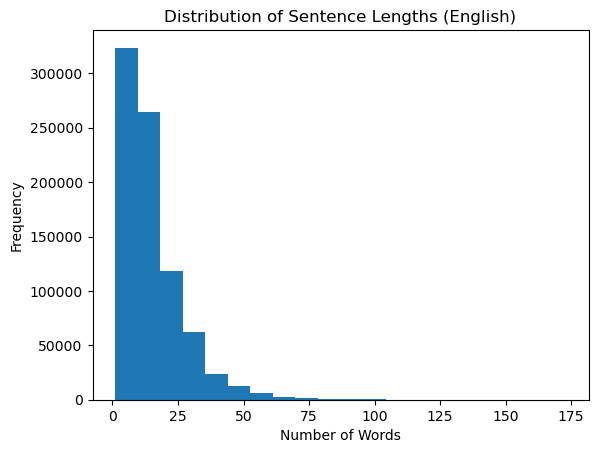

In [33]:
unique_sentences["Word Count_EN"].plot.hist(bins=20)

plt.title("Distribution of Sentence Lengths (English)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

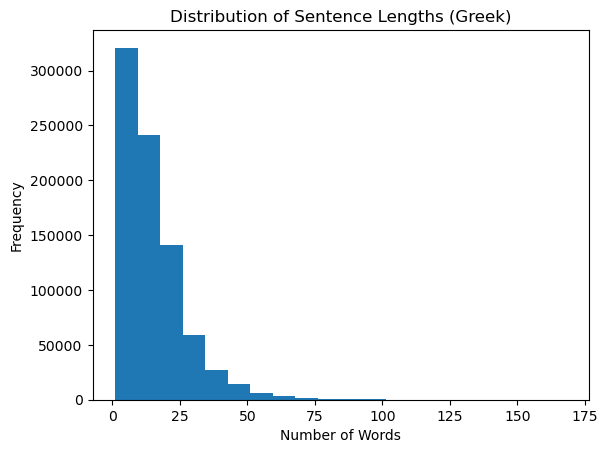

In [34]:
unique_sentences["Word Count_GR"].plot.hist(bins=20)

plt.title("Distribution of Sentence Lengths (Greek)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

We see that the distribution of sentence lengths between the two languages are similar and the majority of them fall between a length of 0-25 words. So, we decide to get rid of the sentences that are too short or too long keeping only sentences that fall in the range 3-25.

3ο Φίλτρο: 'Ελεγχος μήκους

In [35]:
short_sentences = unique_sentences[(unique_sentences["Word Count_GR"] >= 3) & (unique_sentences["Word Count_GR"] <= 25)] 
print(f"Sentences available in the range of 3-25 words: {len(short_sentences)}")

Sentences available in the range of 3-25 words: 687581


In [36]:
print(f"{len(unique_sentences) - len(short_sentences)} have been removed after the application of the lenght filter")

128358 have been removed after the application of the lenght filter


Στατιστικά (μετά τo φίλτρο του μήκους - Φάση 5)

In [37]:
short_sentences.describe()

,Word Count_GR,Word Count_EN
count,687581.000000,687581.000000
mean,11.369273,11.403827
std,6.047488,6.361702
min,3.000000,1.000000
25%,6.000000,6.000000
50%,10.000000,10.000000
75%,16.000000,16.000000
max,25.000000,78.000000


4ο Φίλτρο: Έλεγχος αναλογίας μήκους

In [38]:
# Ορίζουμε το κατώτατο όριο στο 0.3 και ανώτατο το 3.

ratio = short_sentences["Word Count_GR"] / short_sentences["Word Count_EN"]
balanced_pairs = short_sentences[(ratio >= 0.3) & (ratio <= 3)].copy()

print(f"Sentences available in the range of 0.3 to 3 ratio: {len(balanced_pairs)}")

Sentences available in the range of 0.3 to 3 ratio: 687448


In [39]:
print(f"{len(short_sentences) - len(balanced_pairs)} have been removed after the application of the lenght ratio filter")

133 have been removed after the application of the lenght ratio filter


Στατιστικά (μετά τo φίλτρο αναλογίας μήκους - Φάση 6)

In [40]:
balanced_pairs.describe()

,Word Count_GR,Word Count_EN
count,687448.000000,687448.000000
mean,11.370163,11.404157
std,6.047504,6.358551
min,3.000000,1.000000
25%,6.000000,6.000000
50%,10.000000,10.000000
75%,16.000000,16.000000
max,25.000000,74.000000


We see that after applying the three filters (duplicates, lenght, lenght ration) there is enough data to sample our training corpus of 300000 sentences

In [41]:
sampled_df = balanced_pairs.sample(n=300000, random_state=42)

In [42]:
sampled_df.head()

,Greek sentences,English translation,Word Count_GR,Word Count_EN
675595,"Δίκλινο Δωμάτιο, 1 Υπνοδωμάτιο, Θέα στον Κήπο ...","Executive Apartment, 1 Bedroom - Living Area",10,7
158079,"για να επιτύχουμε την επιτυχία, έτσι προσπαθού...","to achieve success, so we strive to provide qu...",12,10
738808,"Στεγνωτήρας μαλλιών, Τουαλέτα, Ραδιόφωνο, Επτρ...","Dining Area, Sofa, Pets Allowed, Mini Bar, Gar...",17,12
46155,Βοηθάει την αξιολόγηση της μυϊκής δύναμης και ...,Helps to assess leg muscular strength and powe...,18,15
373938,Αυτό το εστιατόριο είναι περσικό; Ναι Όχι Άγνωστο,Is this restaurant family-friendly?Yes No Unsure,8,6


In [43]:
# Save to plain text files (one sentence per line, no headers or row numbers)
sampled_df['English translation'].to_csv('english_sentences.txt', index=False, header=False)
sampled_df['Greek sentences'].to_csv('greek_sentences.txt', index=False, header=False)